# 1. Librarys

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import rasterio
import numpy as np
from datetime import datetime, timedelta
import re
import pyproj
import geopandas as gpd
import shapely
import xarray as xr
from rasterio.windows import from_bounds
from concurrent.futures import ThreadPoolExecutor, as_completed
from time import time
import rioxarray
from rasterio.crs import CRS
import statsmodels.formula.api as smf
import glob
from rasterstats import zonal_stats
import tempfile
from tqdm import tqdm
from joblib import Parallel, delayed

# 2. Selected citys

In [6]:
muns = pd.read_excel(r"Bases\soybean_ibge.xlsx")

### Limpeza:
muns['NM_MUN'] = muns['Município'].str.split('(').str[0].str.strip()
muns['SIGLA_UF'] = (
    muns['Município'].str.split('(').str[1].str.replace(')', '').str.strip()
)

muns = muns.drop(columns='Município')
muns = muns.melt(id_vars=['SIGLA_UF', 'NM_MUN'], var_name='YEAR', value_name='PROD_SOJA')

muns['YEAR'] = muns['YEAR'].astype(int)
muns['PROD_SOJA'] = muns['PROD_SOJA'].replace({'-': np.nan, '...': np.nan}, regex=True).astype(float)

### Seleção:
muns = muns[muns['YEAR'].isin(list(range(2006, 2025)))].reset_index(drop=True)
muns = muns.groupby(['SIGLA_UF', 'NM_MUN'], as_index=False).agg({
    'PROD_SOJA': ['mean', 'count']
    })
muns.columns = ['SIGLA_UF', 'NM_MUN', 'PROD_SOJA_MEAN', 'PROD_SOJA_COUNT']

muns = muns[muns['PROD_SOJA_COUNT'] == len(range(2006, 2025))].reset_index(drop=True)
muns = muns.sort_values(by='PROD_SOJA_MEAN', ascending=False).reset_index(drop=True)

muns = muns.head(1000)
muns['code'] = muns['SIGLA_UF'] + '-' + muns['NM_MUN']
muns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   SIGLA_UF         1000 non-null   object 
 1   NM_MUN           1000 non-null   object 
 2   PROD_SOJA_MEAN   1000 non-null   float64
 3   PROD_SOJA_COUNT  1000 non-null   int64  
 4   code             1000 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 39.2+ KB


C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_21984\2665910386.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  muns['PROD_SOJA'] = muns['PROD_SOJA'].replace({'-': np.nan, '...': np.nan}, regex=True).astype(float)


## i. Visual

Longitude Min: -64.2302866, Longitude Max: -43.0880763
Latitude Min: -29.9272629, Latitude Max: 3.7421239


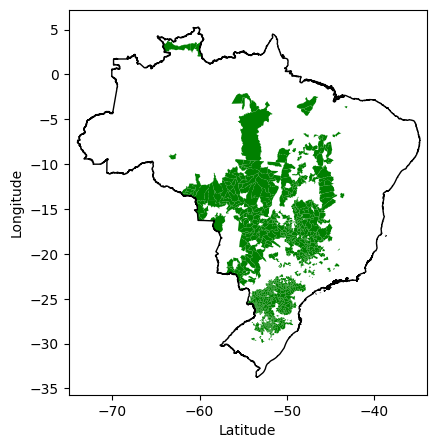

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))

gdf_br = gpd.read_file(r"Bases/BR_Pais_2024/BR_Pais_2024.shp").to_crs("EPSG:4326").boundary
gdf_mun = gpd.read_file(r"Z:\Analytics & BI\Bases de dados\Shapefile Municipios BR\BR_Municipios_2024.shp").to_crs("EPSG:4326")

gdf_br.plot(ax=ax, color='black', linewidth=1)

gdf_mun['code'] = gdf_mun['SIGLA_UF'] + '-' + gdf_mun['NM_MUN']
gdf_mun = gdf_mun[gdf_mun['code'].isin(muns['code'].unique())].reset_index()
municipios = gdf_mun['code'].unique()
gdf_mun.plot(ax=ax, color='g')

long_min, lat_min, long_max, lat_max = gdf_mun['geometry'].total_bounds
print(f"Longitude Min: {long_min}, Longitude Max: {long_max}")
print(f"Latitude Min: {lat_min}, Latitude Max: {lat_max}")

gdf_mun.to_file(r"Bases\municipios_em_uso.shp", driver='ESRI Shapefile')
plt.xlabel('Latitude')
plt.ylabel("Longitude")
plt.xlim(-75, -34)
plt.show()
gdf_mun = gdf_mun.to_crs("EPSG:5880")

## ii. Selected ufs

In [9]:
gdf_mun['SIGLA_UF'].unique()

array(['RS', 'GO', 'MG', 'MT', 'PR', 'SP', 'SC', 'PI', 'TO', 'PA', 'MA',
       'MS', 'RR', 'BA', 'RO', 'DF'], dtype=object)

# 3. Constructing the database

## Individual importing

### i. NDVI

In [ ]:
def export_ndvi():
    path = r"C:\Users\gustavo.ducatti\Downloads\NDVI e SOYBEAN\Bases\NDVI\MOD13C2_061-20251114_131220"
    arquivos = os.listdir(path)
    datasets = []

    gdf_br = gpd.read_file(r"C:\Users\gustavo.ducatti\Downloads\NDVI e SOYBEAN\Bases/BR_Pais_2024/BR_Pais_2024.shp").to_crs("EPSG:4326").boundary
    longmin, latmin, longmax, latmax = gdf_br.total_bounds

    for file in arquivos:
        match = file.split('.')[1][1:]
        date = datetime(year=int(match[:4]), month=1, day=1) + timedelta(days=int(match[4:]) - 1)

        if date.month in [1, 2, 3, 10, 11, 12]:
            ds = xr.open_dataset(path + '\\' + file, engine='netcdf4')
            ds = ds['CMG 0.05 Deg Monthly NDVI']

            ds = ds.rename({
                'YDim:MOD_Grid_monthly_CMG_VI': "y",
                'XDim:MOD_Grid_monthly_CMG_VI': "x"
            })
            lat = 90 - (np.arange(ds.sizes["y"]) + 0.5) * 0.05
            lon = -180 + (np.arange(ds.sizes["x"]) + 0.5) * 0.05

            ds = ds.assign_coords(latitude=("y", lat),
                                    longitude=("x", lon))
            ds = ds.swap_dims({"y": "latitude", "x": "longitude"})

            ds = xr.Dataset(
                data_vars={"ndvi": ds},
                coords={
                    "latitude": ds["latitude"],
                    "longitude": ds["longitude"],
                    "time": [date]
                }
            )

            ds = ds.sel(
                latitude=slice(latmax, latmin),   # Norte até Sul
                longitude=slice(longmin, longmax)   # Oeste até Leste
            ).resample(time="1MS").mean()

            ds["ndvi"] = ds["ndvi"].where((ds["ndvi"] > -2000))  # remove missing
            ds["ndvi"] = ds["ndvi"]  / 1e8

            datasets.append(ds)

    ds = xr.concat(datasets, dim="time")
    ds.to_netcdf(r"Z:\Analytics & BI\Bases de dados\NDVI\ndvi_soja_mensal.nc")

# export_ndvi()

### ii. Rain

In [ ]:
longmin, latmin, longmax, latmax = gdf_br.total_bounds
def export_rain():
    arquivos = sorted(glob.glob(r"Z:\Analytics & BI\Bases de dados\CHIRPS - Monthly\*.nc"))
    datasets = []

    for path in arquivos[5:]:  # a partir de 2005
        print(path)
        ds = xr.open_dataset(path)
        
        ds = ds.assign_coords(
            longitude=((ds.longitude + 180) % 360) - 180
        ).sortby("longitude")
        
        ds = ds.sel(
            latitude=slice(latmin, latmax),   # Norte até Sul
            longitude=slice(longmin, longmax)   # Oeste até Leste
        ).resample(time="1MS").mean()

        ds = ds.sel(time=ds['time'].dt.month.isin([1, 2, 10, 11, 12]))
        datasets.append(ds)

    # --- 3. Concatena todos os dias ---
    ds = xr.concat(datasets, dim="time")
    ds.to_netcdf(r"Z:\Analytics & BI\Bases de dados\CHIRPS - Monthly\full_rain_soja_mensal.nc")

# export_rain()

### iii. Temperature

In [ ]:
def export_temperature():
    arquivos = sorted(glob.glob(r"Z:\Analytics & BI\Bases de dados\ERA5 - Temperature monthly\*.nc"))

    datasets = []

    for i, path in enumerate(arquivos):  # a partir de 2005
        print(2005+i)
        ds = xr.open_dataset(path)
        ds = ds.rename({"valid_time": "time"})
        datasets.append(ds)

    ds = xr.concat(datasets, dim="time").sortby("time")
    ds = ds.resample(time="1MS").max()
    ds = ds.dropna(dim='time', how='all')
    ds.to_netcdf(r"Z:\Analytics & BI\Bases de dados\ERA5 - Temperature monthly\temperature_soja_mensal.nc")

# export_temperature()

## Preparing to concatenate

### i. Raw Base (City - UF - Time)

In [11]:
df_base = gdf_mun[['NM_MUN', 'SIGLA_UF', 'geometry']]

# por memória, selecionar um de cada vez:
# meses = pd.date_range('2005-01-01', '2010-12-01', freq='MS')
# meses = pd.date_range('2010-01-01', '2015-12-01', freq='MS')
# meses = pd.date_range('2015-01-01', '2020-12-01', freq='MS')
# meses = pd.date_range('2020-01-01', '2024-12-01', freq='MS')
meses = pd.date_range('2024-01-01', '2025-12-01', freq='MS')
meses = meses[meses.month.isin([1,2,3,10,11,12])]

years = range(meses[0].year, meses[-1].year + 1)
df_meses = pd.DataFrame({'time': meses})

df_base = df_base.merge(df_meses, how='cross')
df_base = gpd.GeoDataFrame(df_base, geometry=df_base['geometry']).to_crs("EPSG:5880")
df_base.sample(5, random_state=42)

,NM_MUN,SIGLA_UF,geometry,time
1935,Santa Cruz de Goiás,GO,"POLYGON ((5583010.281 8057127.157, 5583013.012...",2024-10-01
6494,Guarantã do Norte,MT,"POLYGON ((4900355.384 8888419.324, 4898176.284...",2024-03-01
1720,Paula Freitas,PR,"POLYGON ((5324926.084 7101525.372, 5325064.79 ...",2024-11-01
9120,Ourizona,PR,"POLYGON ((5188533.553 7413620.911, 5189309.548...",2024-01-01
360,Cambé,PR,"POLYGON ((5282067.192 7413705.681, 5281812.697...",2024-01-01


### ii. Grid function
All months has the same grid, this function use it to optimize the merges

In [12]:
def run_sjoin(ds):
    lats, lons = ds['latitude'].values, ds['longitude'].values
    
    if lats[0] < lats[-1]:
        lats = lats[::-1] 

    if lons[0] > lons[-1]:
        lons = lons[::-1]  # inverte longitudes

    lon_grid, lat_grid = np.meshgrid(lons, lats)
    lon_flat, lat_flat = lon_grid.ravel(), lat_grid.ravel()

    # if 'ndvi' in list(ds.data_vars):
    #     crs_to_use = "ESRI:53008"
    # else:
    #     crs_to_use = "EPSG:4326"
    crs_to_use = "EPSG:4326"
    gdf = gpd.GeoDataFrame(
        {'lon': lon_flat, 'lat': lat_flat},
        geometry=gpd.points_from_xy(lon_flat, lat_flat),
        crs=crs_to_use
        )

    gdf = gdf.to_crs("EPSG:5880")
    mapping = gpd.sjoin_nearest(df_base, gdf, distance_col="dist", how='left')
    return mapping[['NM_MUN', 'SIGLA_UF', 'lon', 'lat', 'dist']]

### iii. Melting function

In [13]:
def yearly_format(df_to_format, var):
    df = df_to_format.copy()
    df['YEAR'] = df['time'].dt.year
    df['MONTH'] = df['time'].dt.month

    # Criar colunas para meses do ano anterior
    df['YEAR_LAST'] = df['YEAR'] - 1

    # Selecionar os meses de interesse
    df_months = df[df['MONTH'].isin([10,11,12,1,2,3])].copy()

    # Para os meses de setembro a dezembro do ano anterior
    df_months_last = df_months[df_months['MONTH'].isin([10,11,12])].copy()
    df_months_last['YEAR'] = df_months_last['YEAR'] + 1  # Para alinhar com o ano atual

    # Pivot para os meses do ano anterior
    df_ly = df_months_last.pivot_table(
        index=['NM_MUN','SIGLA_UF','YEAR'],
        columns='MONTH',
        values=var
    ).rename(columns={
        10: f'{var}_10_ly',
        11: f'{var}_11_ly',
        12: f'{var}_12_ly'
    }).reset_index()

    # Para os meses 1 e 2 do ano atual
    df_current = df_months[df_months['MONTH'].isin([1, 2, 3])].pivot_table(
        index=['NM_MUN','SIGLA_UF','YEAR'],
        columns='MONTH',
        values=var
    ).rename(columns={
        1: f'{var}_01',
        2: f'{var}_02',
        3: f'{var}_03'
    }).reset_index()

    # Merge final
    df_wide = pd.merge(df_ly, df_current, on=['NM_MUN','SIGLA_UF','YEAR'], how='outer').reset_index(drop=True)
    df_wide.columns.name = None

    # Resultado
    return df_wide

## Concatenating

Serão realizados dois merges - para ter certeza da existencia de todos os municipios em todos os anos.
* 1. df_base => run_sjoin (pegar, para cada municipio, as coordenadas na malha que devem entrar em seu calculo)
* 2. => df_ds (pegar na malha, dadas as cordenadas, o valor da variável)

note que o primeiro merge tambem ja serve para incluir a data, utilizada no merge 2

### i. Temperature

In [14]:
df_ds = xr.open_dataset(r"Z:\Analytics & BI\Bases de dados\ERA5 - Temperature monthly\temperature_soja_mensal.nc")

df_merged = df_base[['NM_MUN', 'SIGLA_UF', 'time']].merge(
    run_sjoin(
        df_ds.sel(time=meses[0], method='nearest')
    )[['NM_MUN', 'SIGLA_UF', 'lon', 'lat']],
    how='left',
    left_on=['NM_MUN', 'SIGLA_UF'],  
    right_on=['NM_MUN', 'SIGLA_UF']
    )

df_ds = df_ds.to_dataframe().reset_index()  # cria colunas: time, latitude, longitude, t2m

df_merged = df_merged.merge(
    df_ds[['latitude', 'longitude', 'time', 't2m']],
    how='left',
    left_on=['lat', 'lon', 'time'],  
    right_on=['latitude', 'longitude', 'time']
)

df_merged = df_merged.groupby(['NM_MUN', 'SIGLA_UF', 'time'], as_index=False)['t2m'].max().sort_values(by=['NM_MUN', 'time'])
# df_merged.to_csv(f"Bases/temperature_{years}.csv", index=False, encoding='latin1')
df = yearly_format(df_merged, 't2m')
df = df[df['YEAR'].between(years[0] + 1, years[-1])].reset_index(drop=True)
df.sample(6, random_state=1)

,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02
507,Machadinho,RS,2025,304.500732,304.196533,303.567627,305.590332,305.968262
818,Sapopema,PR,2025,308.343018,306.380127,304.456543,303.608154,306.356201
452,Jaciara,MT,2025,313.927246,307.583740,306.751465,306.844727,307.590332
368,Guarujá do Sul,SC,2025,306.789062,304.637939,303.503174,306.233643,305.867676
242,Coronel Vivida,PR,2025,305.978516,302.716064,301.625488,303.959961,304.010254
929,Treze Tílias,SC,2025,303.509766,302.778564,301.445801,303.156738,303.246582


### ii. Rain

In [15]:
df_ds = xr.open_dataset(r"Z:\Analytics & BI\Bases de dados\CHIRPS - Monthly\full_rain_soja_mensal.nc")

df_merged = df_base[['NM_MUN', 'SIGLA_UF', 'time']].merge(
run_sjoin(
    df_ds.sel(time=meses[0], method='nearest')
    )[['NM_MUN', 'SIGLA_UF', 'lon', 'lat']],
    how='left',
    left_on=['NM_MUN', 'SIGLA_UF'],  
    right_on=['NM_MUN', 'SIGLA_UF']
    )

df_ds = df_ds.to_dataframe().reset_index()  # cria colunas: time, latitude, longitude, precip
df_ds['time'] = df_ds['time'].dt.to_period('M').dt.to_timestamp()

df_merged = df_merged.merge(
    df_ds[['latitude', 'longitude', 'time', 'precip']],
    how='left',
    left_on=['lat', 'lon', 'time'],  
    right_on=['latitude', 'longitude', 'time']
)

df_merged = df_merged.groupby(['NM_MUN', 'SIGLA_UF', 'time'], as_index=False)['precip'].mean().sort_values(by=['NM_MUN', 'time'])
# df_merged.to_csv(f"Bases/precip_{years}_1.csv", index=False, encoding='latin1')
df = df.merge(yearly_format(df_merged, 'precip'), on=['NM_MUN', 'SIGLA_UF', 'YEAR'], how='left')
df = df[df['YEAR'].between(years[0] + 1, years[-1])].reset_index(drop=True)
df

,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02,precip_10_ly,precip_11_ly,precip_12_ly,precip_01,precip_02
0,Abadia dos Dourados,MG,2025,310.460205,304.273682,305.247559,304.255371,306.320068,146.827347,299.817047,412.513367,255.713348,115.236328
1,Abadiânia,GO,2025,309.485840,302.993408,304.915527,304.453857,304.768555,208.055115,277.704193,278.662292,265.887939,127.662178
2,Abatiá,PR,2025,311.833252,310.508789,306.702637,306.674316,308.925537,99.659996,163.663666,200.298294,171.741409,108.518951
3,Abdon Batista,SC,2025,302.824219,302.860596,301.661377,303.791504,304.129395,185.402969,136.845535,180.551712,97.352272,161.060349
4,Abelardo Luz,SC,2025,304.072266,302.264893,301.615723,303.172363,302.912354,152.423706,151.572159,150.473389,110.866982,151.389313
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Água Santa,RS,2025,302.884521,303.817627,302.855713,304.631348,304.479004,235.472733,82.594818,191.249466,87.400635,117.016754
996,Águas de Santa Bárbara,SP,2025,309.281738,307.647461,305.678955,305.518311,306.546631,167.348557,112.424179,219.418457,153.391907,112.213379
997,Áurea,RS,2025,303.740234,304.083252,303.522705,305.223145,305.194824,197.800171,148.758377,180.608841,119.927574,129.103851
998,Ângulo,PR,2025,311.111328,308.928955,306.479980,306.679443,308.001709,94.838341,211.150467,218.019363,163.262253,106.596283


### iii. NDVI

In [16]:
df_ds = xr.open_dataset(r"Z:\Analytics & BI\Bases de dados\NDVI\ndvi_soja_mensal.nc")

df_merged = df_base[['NM_MUN', 'SIGLA_UF', 'time']].merge(
run_sjoin(
    df_ds.sel(time=meses[0], method='nearest')
    )[['NM_MUN', 'SIGLA_UF', 'lon', 'lat']],
    how='left',
    left_on=['NM_MUN', 'SIGLA_UF'],  
    right_on=['NM_MUN', 'SIGLA_UF']
    )

df_ds = df_ds.to_dataframe().reset_index()  # cria colunas: time, latitude, longitude, ndvi
df_ds['time'] = df_ds['time'].dt.to_period('M').dt.to_timestamp()

df_merged = df_merged.merge(
    df_ds[['latitude', 'longitude', 'time', 'ndvi']],
    how='left',
    left_on=['lat', 'lon', 'time'],  
    right_on=['latitude', 'longitude', 'time']
)

df_merged = df_merged.groupby(['NM_MUN', 'SIGLA_UF', 'time'], as_index=False)['ndvi'].mean().sort_values(by=['NM_MUN', 'time'])
# df_merged.to_csv(f"Bases/ndvi_{years}_1.csv", index=False, encoding='latin1')
df = df.merge(yearly_format(df_merged, 'ndvi'), on=['NM_MUN', 'SIGLA_UF', 'YEAR'], how='left')
df = df[df['YEAR'].between(years[0] + 1, years[-1])].reset_index(drop=True)
df

,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02,precip_10_ly,precip_11_ly,precip_12_ly,precip_01,precip_02,ndvi_10_ly,ndvi_11_ly,ndvi_12_ly,ndvi_01,ndvi_02,ndvi_03
0,Abadia dos Dourados,MG,2025,310.460205,304.273682,305.247559,304.255371,306.320068,146.827347,299.817047,412.513367,255.713348,115.236328,0.459533,0.604290,0.700363,0.755933,0.737663,0.643567
1,Abadiânia,GO,2025,309.485840,302.993408,304.915527,304.453857,304.768555,208.055115,277.704193,278.662292,265.887939,127.662178,0.447389,0.611732,0.728232,0.776424,0.703616,0.677076
2,Abatiá,PR,2025,311.833252,310.508789,306.702637,306.674316,308.925537,99.659996,163.663666,200.298294,171.741409,108.518951,0.454743,0.591771,0.804171,0.765586,0.814186,0.651771
3,Abdon Batista,SC,2025,302.824219,302.860596,301.661377,303.791504,304.129395,185.402969,136.845535,180.551712,97.352272,161.060349,0.740988,0.724687,0.746387,0.809813,0.822462,0.793475
4,Abelardo Luz,SC,2025,304.072266,302.264893,301.615723,303.172363,302.912354,152.423706,151.572159,150.473389,110.866982,151.389313,0.616291,0.602677,0.764280,0.838143,0.806634,0.717934
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Água Santa,RS,2025,302.884521,303.817627,302.855713,304.631348,304.479004,235.472733,82.594818,191.249466,87.400635,117.016754,0.650082,0.487091,0.637982,0.834064,0.822782,0.720791
996,Águas de Santa Bárbara,SP,2025,309.281738,307.647461,305.678955,305.518311,306.546631,167.348557,112.424179,219.418457,153.391907,112.213379,0.514950,0.585321,0.694464,0.728914,0.760779,0.652300
997,Áurea,RS,2025,303.740234,304.083252,303.522705,305.223145,305.194824,197.800171,148.758377,180.608841,119.927574,129.103851,0.673733,0.503767,0.622567,0.789183,0.811583,0.720933
998,Ângulo,PR,2025,311.111328,308.928955,306.479980,306.679443,308.001709,94.838341,211.150467,218.019363,163.262253,106.596283,0.395233,0.569400,0.761000,0.743833,0.598067,0.579933


### iv. Production

In [17]:
df_prod = pd.read_excel(r"Bases\soybean_ibge.xlsx")

df_prod['NM_MUN'] = df_prod['Município'].str.split('(').str[0].str.strip()
df_prod['SIGLA_UF'] = (
    df_prod['Município'].str.split('(').str[1].str.replace(')', '').str.strip()
)
df_prod['code'] = df_prod['SIGLA_UF'] + '-' + df_prod['NM_MUN']
df_prod = df_prod[df_prod['code'].isin(municipios)].reset_index(drop=True)
df_prod = df_prod.drop(columns=['Município', 'code'])

df_prod = df_prod.melt(id_vars=['SIGLA_UF', 'NM_MUN'], var_name='YEAR', value_name='PROD_SOJA')

df_prod['YEAR'] = df_prod['YEAR'].astype(int)
df_prod['PROD_SOJA'] = df_prod['PROD_SOJA'].replace({'-': np.nan, '...': np.nan}, regex=True).astype(float)

df_prod = df_prod[df_prod['YEAR'].between(years[0], years[-1])].reset_index(drop=True)
df_prod.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   SIGLA_UF   1000 non-null   object 
 1   NM_MUN     1000 non-null   object 
 2   YEAR       1000 non-null   int64  
 3   PROD_SOJA  1000 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 31.4+ KB


C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_21984\2760584610.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_prod['PROD_SOJA'] = df_prod['PROD_SOJA'].replace({'-': np.nan, '...': np.nan}, regex=True).astype(float)


### v. Final df

In [19]:
df = df.merge(df_prod, on=['SIGLA_UF', 'NM_MUN', 'YEAR'], how='left')
for c in df.columns:
    if 't2m' in c:
        df[c] = df[c] - 273.15

df

,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02,precip_10_ly,precip_11_ly,precip_12_ly,precip_01,precip_02,ndvi_10_ly,ndvi_11_ly,ndvi_12_ly,ndvi_01,ndvi_02,ndvi_03,PROD_SOJA
0,Abadia dos Dourados,MG,2025,37.310211,31.123688,32.097565,31.105377,33.170074,146.827347,299.817047,412.513367,255.713348,115.236328,0.459533,0.604290,0.700363,0.755933,0.737663,0.643567,NaN
1,Abadiânia,GO,2025,36.335846,29.843414,31.765533,31.303864,31.618561,208.055115,277.704193,278.662292,265.887939,127.662178,0.447389,0.611732,0.728232,0.776424,0.703616,0.677076,NaN
2,Abatiá,PR,2025,38.683258,37.358795,33.552643,33.524323,35.775543,99.659996,163.663666,200.298294,171.741409,108.518951,0.454743,0.591771,0.804171,0.765586,0.814186,0.651771,NaN
3,Abdon Batista,SC,2025,29.674225,29.710602,28.511383,30.641510,30.979401,185.402969,136.845535,180.551712,97.352272,161.060349,0.740988,0.724687,0.746387,0.809813,0.822462,0.793475,NaN
4,Abelardo Luz,SC,2025,30.922272,29.114899,28.465729,30.022369,29.762360,152.423706,151.572159,150.473389,110.866982,151.389313,0.616291,0.602677,0.764280,0.838143,0.806634,0.717934,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Água Santa,RS,2025,29.734528,30.667633,29.705719,31.481354,31.329010,235.472733,82.594818,191.249466,87.400635,117.016754,0.650082,0.487091,0.637982,0.834064,0.822782,0.720791,NaN
996,Águas de Santa Bárbara,SP,2025,36.131744,34.497467,32.528961,32.368317,33.396637,167.348557,112.424179,219.418457,153.391907,112.213379,0.514950,0.585321,0.694464,0.728914,0.760779,0.652300,NaN
997,Áurea,RS,2025,30.590240,30.933258,30.372711,32.073151,32.044830,197.800171,148.758377,180.608841,119.927574,129.103851,0.673733,0.503767,0.622567,0.789183,0.811583,0.720933,NaN
998,Ângulo,PR,2025,37.961334,35.778961,33.329987,33.529449,34.851715,94.838341,211.150467,218.019363,163.262253,106.596283,0.395233,0.569400,0.761000,0.743833,0.598067,0.579933,NaN


# 4. Exporting

In [20]:
df.to_csv(f"Bases/{years}_final_data.csv", index=False)